# Corrélation ret_BTC vs ret_ETH
Cette cellule charge le fichier `data/multi_asset_dataset.csv`, extrait les colonnes `ret_BTC` et `ret_ETH`, et trace un nuage de points avec la droite de régression et le coefficient de corrélation (Pearson).

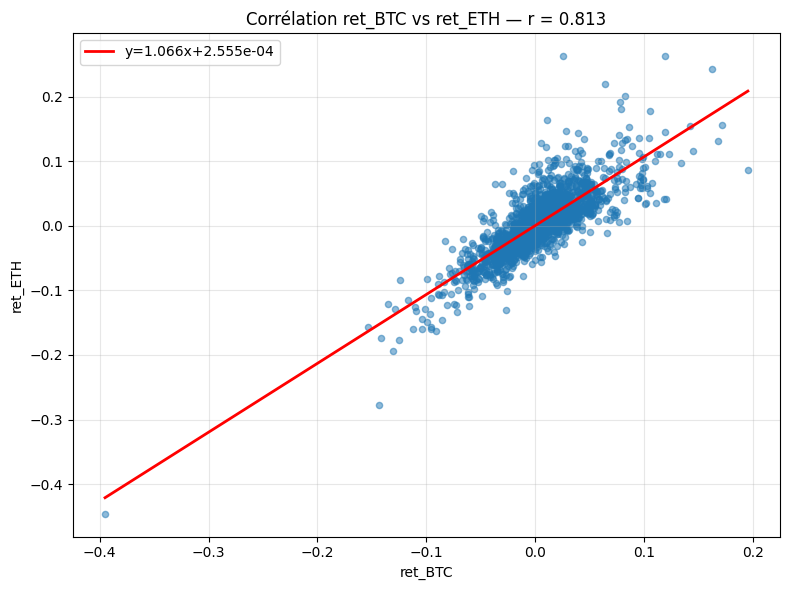

Observations utilisées: 2496
Pearson r = 0.8134
          count      mean       std       min       25%       50%       75%  \
ret_BTC  2496.0  0.001906  0.033081 -0.395048 -0.012407  0.000709  0.015521   
ret_ETH  2496.0  0.002288  0.043369 -0.445969 -0.017932  0.001121  0.021706   

              max  
ret_BTC  0.195361  
ret_ETH  0.263329  


In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Charger le dataset
path = './data/bitcoin_with_fear_greed_fed_data_final.xlsx'
df = pd.read_excel(path, parse_dates=['date'])

# Extraire les rendements BTC et ETH
cols = ['ret_BTC', 'ret_ETH']
if not all(c in df.columns for c in cols):
    missing = [c for c in cols if c not in df.columns]
    raise FileNotFoundError(f"Colonnes manquantes dans {path}: {missing}")

s = df[cols].copy().dropna()
if s.empty:
    raise ValueError('Aucune paire de rendements disponible (après suppression des NaN)')

# Calcul du coefficient de Pearson
r = s['ret_BTC'].corr(s['ret_ETH'])

# Nuage + droite de régression
plt.figure(figsize=(8,6))
plt.scatter(s['ret_BTC'], s['ret_ETH'], alpha=0.5, s=20)
# droite de régression
m, b = np.polyfit(s['ret_BTC'], s['ret_ETH'], 1)
x = np.linspace(s['ret_BTC'].min(), s['ret_BTC'].max(), 200)
plt.plot(x, m * x + b, color='red', lw=2, label=f"y={m:.3f}x+{b:.3e}")

plt.title(f"Corrélation ret_BTC vs ret_ETH — r = {r:.3f}")
plt.xlabel('ret_BTC')
plt.ylabel('ret_ETH')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Afficher quelques statistiques supplémentaires
print(f"Observations utilisées: {len(s)}")
print(f"Pearson r = {r:.4f}")
print(s[['ret_BTC','ret_ETH']].describe().T)

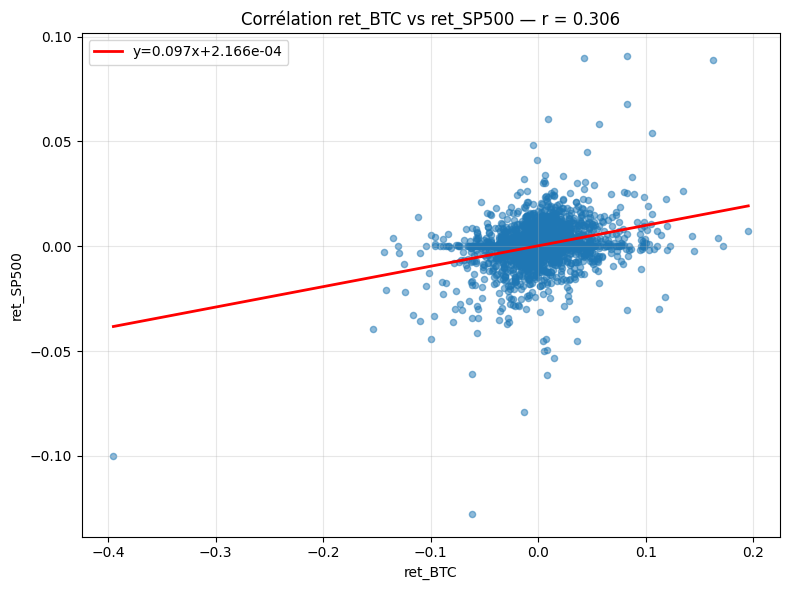

Observations utilisées: 2495
Pearson r = 0.3061
            count      mean       std       min       25%       50%       75%  \
ret_BTC    2495.0  0.001901  0.033086 -0.395048 -0.012441  0.000709  0.015488   
ret_SP500  2495.0  0.000402  0.010534 -0.127652 -0.001601  0.000000  0.003762   

                max  
ret_BTC    0.195361  
ret_SP500  0.090895  


In [5]:
cols_sp = ['ret_BTC', 'ret_SP500']
missing = [c for c in cols_sp if c not in df.columns]
if missing:
    raise FileNotFoundError(f"Colonnes manquantes: {missing}")

t = df[cols_sp].dropna()
if t.empty:
    raise ValueError("Aucune paire BTC / S&P500 disponible (après suppression des NaN)")

r_sp = t['ret_BTC'].corr(t['ret_SP500'])

plt.figure(figsize=(8, 6))
plt.scatter(t['ret_BTC'], t['ret_SP500'], alpha=0.5, s=20)

m_sp, b_sp = np.polyfit(t['ret_BTC'], t['ret_SP500'], 1)
x_sp = np.linspace(t['ret_BTC'].min(), t['ret_BTC'].max(), 200)
plt.plot(x_sp, m_sp * x_sp + b_sp, color='red', lw=2, label=f"y={m_sp:.3f}x+{b_sp:.3e}")

plt.title(f"Corrélation ret_BTC vs ret_SP500 — r = {r_sp:.3f}")
plt.xlabel('ret_BTC')
plt.ylabel('ret_SP500')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Observations utilisées: {len(t)}")
print(f"Pearson r = {r_sp:.4f}")
print(t.describe().T)


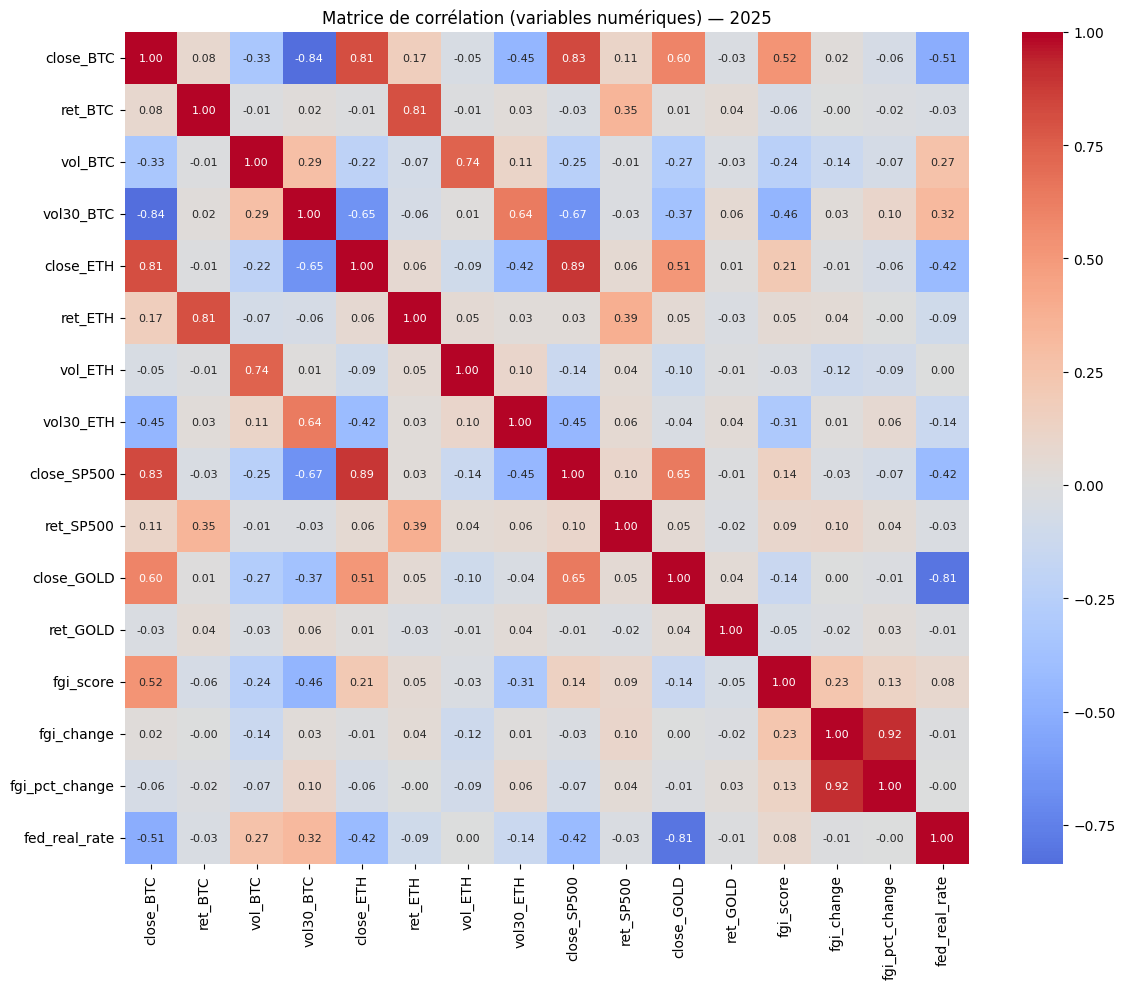

,close_BTC,ret_BTC,vol_BTC,vol30_BTC,close_ETH,ret_ETH,vol_ETH,vol30_ETH,close_SP500,ret_SP500,close_GOLD,ret_GOLD,fgi_score,fgi_change,fgi_pct_change,fed_real_rate
close_BTC,1.000000,0.082019,-0.333700,-0.837233,0.813113,0.174037,-0.046227,-0.453383,0.832857,0.110602,0.595180,-0.028546,0.520541,0.020934,-0.057288,-0.512128
ret_BTC,0.082019,1.000000,-0.007441,0.020820,-0.005129,0.805340,-0.007680,0.026104,-0.034844,0.345643,0.005681,0.038434,-0.057240,-0.002190,-0.023971,-0.034607
vol_BTC,-0.333700,-0.007441,1.000000,0.287912,-0.217036,-0.070422,0.736655,0.112398,-0.248038,-0.013892,-0.273851,-0.029999,-0.236145,-0.137717,-0.065502,0.266711
vol30_BTC,-0.837233,0.020820,0.287912,1.000000,-0.654273,-0.059144,0.010999,0.639976,-0.669990,-0.025831,-0.368381,0.058880,-0.462236,0.025678,0.096737,0.321003
close_ETH,0.813113,-0.005129,-0.217036,-0.654273,1.000000,0.063993,-0.091262,-0.415256,0.891233,0.055591,0.505587,0.014973,0.211512,-0.011358,-0.060598,-0.423755
ret_ETH,0.174037,0.805340,-0.070422,-0.059144,0.063993,1.000000,0.046893,0.027792,0.025757,0.385685,0.050281,-0.028619,0.052501,0.042278,-0.000986,-0.094830
vol_ETH,-0.046227,-0.007680,0.736655,0.010999,-0.091262,0.046893,1.000000,0.102439,-0.137500,0.042947,-0.098624,-0.006920,-0.029729,-0.116623,-0.088965,0.000573
vol30_ETH,-0.453383,0.026104,0.112398,0.639976,-0.415256,0.027792,0.102439,1.000000,-0.447955,0.056211,-0.038526,0.036258,-0.310512,0.013216,0.061608,-0.137623
close_SP500,0.832857,-0.034844,-0.248038,-0.669990,0.891233,0.025757,-0.137500,-0.447955,1.000000,0.099426,0.647841,-0.011182,0.140073,-0.026339,-0.067985,-0.423182
ret_SP500,0.110602,0.345643,-0.013892,-0.025831,0.055591,0.385685,0.042947,0.056211,0.099426,1.000000,0.050668,-0.018075,0.091017,0.099149,0.044226,-0.030013


In [ ]:
2